# 04 — Résultats et conclusions

Le script `scripts/04_entrainer.py` a refait les essais du notebook 03 sur **toutes les stations**, avec la même validation par station en 5 plis. Ce notebook ne réentraîne rien : il lit les prédictions sauvegardées (`data/predictions/`), le tableau `reports/resultats.csv` et le journal `reports/runs.csv`.

La question métier : **une fois corrigé, un capteur SDS011 à environ 30 € donne-t-il une mesure de PM2.5 assez proche d'une station officielle pour être utile, là où il n'y a pas de station ?**

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from aircalib import parametres as P
from aircalib.metriques import stats_regression

pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(150)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIGURES = P.RAPPORTS / "figures"
PREDICTIONS = P.dossier_donnees() / "predictions"
resultats = pl.read_csv(P.RAPPORTS / "resultats.csv")
journal = pl.read_csv(P.RAPPORTS / "runs.csv")
COLONNES = [
    "modele",
    "rmse",
    "mae",
    "r2_median_par_paire",
    "pente_mediane_par_paire",
    "pct_epa_horaire",
    "pct_epa_journalier",
]
resultats.filter(pl.col("paires") == "saines", pl.col("tranche") == "toutes heures").select(COLONNES)

modele,rmse,mae,r2_median_par_paire,pente_mediane_par_paire,pct_epa_horaire,pct_epa_journalier
str,f64,f64,f64,f64,f64,f64
"""0_capteur_brut""",12.417,5.164,0.687,0.621,25.298,40.931
"""1_regression_lineaire""",7.05,4.518,0.376,0.192,0.0,0.0
"""2_lightgbm""",3.79,2.317,0.85,0.795,73.986,84.804
"""3_lightgbm_reglage_1""",3.73,2.282,0.855,0.813,75.656,86.52
"""4_lightgbm_sans_voisins""",4.698,2.907,0.792,0.676,49.642,65.441
"""5_lightgbm_combine""",3.744,2.295,0.851,0.803,75.656,86.52


Sur les 419 paires saines (4,4 millions d'heures, chaque station prédite par un modèle qui ne l'a jamais vue), le modèle retenu (`5_lightgbm_combine`) donne :
- **75,7 % des paires EPA en horaire** (317 paires sur 419), contre 25,3 % pour le capteur brut ;
- **86,5 % en journalier**, contre 40,9 % ;
- un RMSE divisé par 3,3 (de 12,4 à 3,7 µg/m³) et un MAE divisé par 2,2 (de 5,2 à 2,3) ;
- un R² médian de 0,85 et une pente médiane de 0,80.

Les autres lignes confirment les choix du notebook 03 :
- **La régression linéaire** est encore plus mauvaise sur toutes les stations (pente médiane 0,19, aucune paire EPA). Le PM2.5 brut y monte jusqu'à 990 µg/m³, ce qui écrase encore plus son coefficient.
- **Le réglage 1** atteint le même 75,7 %, mais en 5 fois plus de temps. Le LightGBM complet seul fait 74,0 %.
- **La combinaison** gagne donc 7 paires sur le LightGBM complet, sans aucun entraînement supplémentaire.

## 1. Paire par paire

Le pourcentage EPA résume tout en un chiffre. On regarde plutôt chaque paire : son $R^2$ et sa pente, avant et après correction. Le cadre noir délimite les cibles EPA sur ces deux critères.

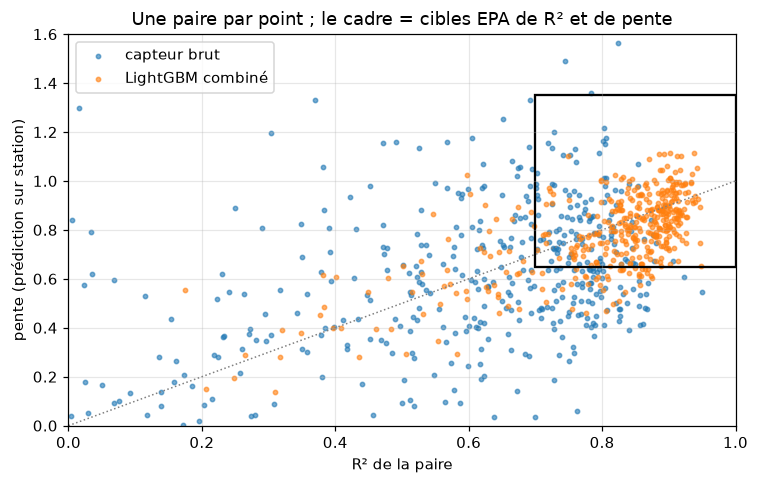

In [2]:
brut = pl.read_parquet(PREDICTIONS / "0_capteur_brut.parquet")
lgb = pl.read_parquet(PREDICTIONS / "5_lightgbm_combine.parquet")
par_paire = pl.concat(
    [
        stats_regression(p.filter(pl.col("paire_saine")), ["capteur"])
        .filter(pl.col("n") >= P.HEURES_MIN_PAIRE)
        .with_columns(modele=pl.lit(nom))
        for nom, p in [("capteur brut", brut), ("LightGBM combiné", lgb)]
    ]
)
fig, ax = plt.subplots(figsize=(7, 4.5))
for (nom,), groupe in par_paire.group_by("modele", maintain_order=True):
    ax.scatter(groupe["r2"], groupe["pente"], s=8, alpha=0.6, label=nom)
ax.add_patch(
    plt.Rectangle(
        (P.EPA_R2_MIN, P.EPA_PENTE[0]),
        1 - P.EPA_R2_MIN,
        P.EPA_PENTE[1] - P.EPA_PENTE[0],
        fill=False,
        ec="k",
        lw=1.5,
    )
)
ax.plot([0, 1], [0, 1], color="grey", ls=":", lw=1)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.6)
ax.set_xlabel("R² de la paire")
ax.set_ylabel("pente (prédiction sur station)")
ax.set_title("Une paire par point ; le cadre = cibles EPA de R² et de pente")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "04_paires_avant_apres.png")

Le nuage du capteur brut (en bleu) est très étalé : des $R^2$ de 0 à 0,95, des pentes de 0 à 1,5. Après correction (en orange), les paires se regroupent entre 0,75 et 0,95 de $R^2$, avec des pentes de 0,65 à 1,1, **le long de la diagonale pointillée** : c'est la relation « pente ≈ R² » du notebook 03.

Sur les 102 paires qui échouent encore, 81 ont une pente trop basse (< 0,65), 63 un $R^2$ trop faible, et seulement 12 une ordonnée hors cible et 9 un RMSE trop grand (une paire peut échouer sur plusieurs critères).

**Ce que ça veut dire :** le défaut qui reste, c'est la **sous-estimation des variations**. Le modèle suit bien la forme, mais il ne monte pas assez haut pendant les pics.

Pour se faire une idée concrète, voici une paire « moyenne » (R² proche de la médiane), sur trois semaines d'hiver :

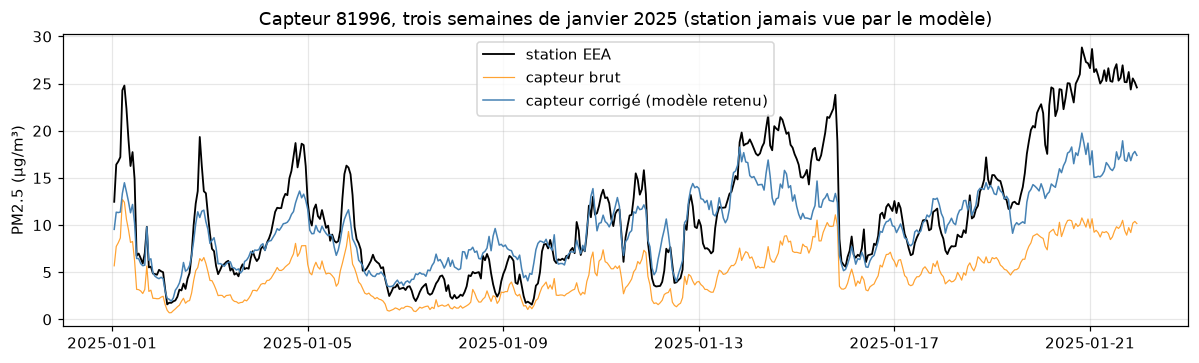

In [3]:
capteur = (
    par_paire.filter(pl.col("modele") == "LightGBM combiné")
    .sort("n", descending=True)
    .filter(pl.col("r2").is_between(par_paire["r2"].quantile(0.4), par_paire["r2"].quantile(0.6)))["capteur"][
        0
    ]
)
fenetre = (
    lgb.filter(
        pl.col("capteur") == capteur, pl.col("heure").dt.month() == 1, pl.col("heure").dt.year() == 2025
    )
    .join(brut.select("capteur", "heure", brut="prediction"), on=["capteur", "heure"])
    .filter(pl.col("heure").dt.day() <= 21)
)
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(fenetre["heure"], fenetre["reference"], color="k", lw=1.2, label="station EEA")
ax.plot(fenetre["heure"], fenetre["brut"], color="darkorange", lw=0.8, alpha=0.8, label="capteur brut")
ax.plot(
    fenetre["heure"], fenetre["prediction"], color="steelblue", lw=1, label="capteur corrigé (modèle retenu)"
)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title(f"Capteur {capteur}, trois semaines de janvier 2025 (station jamais vue par le modèle)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "04_exemple_de_serie.png")

Le capteur brut (orange) suit la forme de la courbe de la station, mais deux à trois fois trop bas. Le capteur corrigé (bleu) recolle au bon niveau la plupart du temps, y compris dans les creux. En revanche, il reste **en dessous de la station pendant les épisodes les plus pollués** (14–15 janvier, puis à partir du 19) : c'est exactement la pente inférieure à 1 vue juste au-dessus.

## 2. Où le modèle est-il bon, où l'est-il moins ?

On découpe les heures des paires saines selon deux critères :
- le capteur a-t-il au moins 3 voisins à cette heure ?
- à quelle distance est-il de sa station ? (0–0,5 / 0,5–1 / 1–1,5 km)

In [4]:
tranches = [
    "toutes heures",
    "avec voisins",
    "sans voisins",
    "bande 0-0,5 km",
    "bande 0,5-1 km",
    "bande 1-1,5 km",
]
(
    resultats.filter(
        pl.col("paires") == "saines", pl.col("modele").is_in(["0_capteur_brut", "5_lightgbm_combine"])
    )
    .select(
        "modele",
        "tranche",
        "heures",
        "paires_notees",
        "rmse",
        "r2_median_par_paire",
        "pct_epa_horaire",
        "pct_epa_journalier",
    )
    .sort(pl.col("tranche").replace_strict(tranches, list(range(len(tranches)))), "modele")
)

modele,tranche,heures,paires_notees,rmse,r2_median_par_paire,pct_epa_horaire,pct_epa_journalier
str,str,i64,i64,f64,f64,f64,f64
"""0_capteur_brut""","""toutes heures""",4401479,419,12.417,0.687,25.298,40.931
"""5_lightgbm_combine""","""toutes heures""",4401479,419,3.744,0.851,75.656,86.52
"""0_capteur_brut""","""avec voisins""",3539222,357,13.381,0.694,26.611,40.0
"""5_lightgbm_combine""","""avec voisins""",3539222,357,3.449,0.867,83.473,91.594
"""0_capteur_brut""","""sans voisins""",862257,108,7.216,0.605,22.222,43.182
"""5_lightgbm_combine""","""sans voisins""",862257,108,4.769,0.763,44.444,62.5
"""0_capteur_brut""","""bande 0-0,5 km""",1113971,105,8.804,0.708,27.619,39.216
"""5_lightgbm_combine""","""bande 0-0,5 km""",1113971,105,3.411,0.865,80.0,88.235
"""0_capteur_brut""","""bande 0,5-1 km""",1481963,142,17.557,0.684,26.761,40.0


- **Avec des voisins** (80 % des heures) : **83,5 % des paires EPA** en horaire, 91,6 % en journalier, avec un RMSE de 3,4.
- **Sans voisins** (20 % des heures) : 44,4 % et 62,5 %, avec un RMSE de 4,8. C'est mieux que le brut (22 % et 43 %), mais c'est clairement le point faible.
- **Selon la distance** capteur–station : 80,0 % entre 0 et 0,5 km, 74,6 % entre 0,5 et 1 km, 73,8 % entre 1 et 1,5 km.

**Ce que ça veut dire :**
- Ce qui compte le plus, c'est d'**avoir des voisins**, bien plus que la distance à la station.
- Les paires très proches sont un peu meilleures, parce que capteur et station y voient vraiment le même air. Mais au-delà de 500 m, les résultats ne bougent presque plus : notre rayon de 1,5 km ne fausse pas l'évaluation.

## 3. Les conclusions de l'échantillon tiennent-elles ?

Le journal des essais garde chaque entraînement. On compare l'échantillon de 20 % des stations (notebook 03) et toutes les stations. Les lignes « voisins = capteurs appariés seulement » viennent de notre premier essai complet, avant qu'on ajoute les capteurs voisins non appariés (notebook 02, partie 5).

In [5]:
(
    journal.filter(
        pl.col("modele").is_in(
            [
                "0_capteur_brut",
                "1_regression_lineaire",
                "2_lightgbm",
                "3_lightgbm_reglage_1",
                "4_lightgbm_sans_voisins",
                "5_lightgbm_combine",
            ]
        )
    )
    .select(
        "perimetre",
        "modele",
        "heures_test",
        "rmse",
        "r2_median_par_paire",
        "pct_epa_horaire",
        "pct_epa_journalier",
        "rmse_sans_voisins",
    )
    .sort("modele", "perimetre")
)

perimetre,modele,heures_test,rmse,r2_median_par_paire,pct_epa_horaire,pct_epa_journalier,rmse_sans_voisins
str,str,i64,f64,f64,f64,f64,f64
"""toutes les stations""","""0_capteur_brut""",4401479,12.417,0.687,25.3,40.9,7.216
"""toutes les stations ; voisins = capteurs appariés seulement""","""0_capteur_brut""",4401479,12.417,0.687,25.3,40.9,7.29
"""échantillon : 20 % des stations""","""0_capteur_brut""",611221,7.086,0.711,21.7,32.8,8.126
"""toutes les stations""","""1_regression_lineaire""",4401479,7.05,0.376,0.0,0.0,6.556
"""toutes les stations ; voisins = capteurs appariés seulement""","""1_regression_lineaire""",4401479,7.05,0.376,0.0,0.0,6.468
"""échantillon : 20 % des stations""","""1_regression_lineaire""",611221,5.812,0.672,8.3,10.3,6.631
"""toutes les stations""","""2_lightgbm""",4401479,3.79,0.85,74.0,84.8,4.951
"""toutes les stations ; voisins = capteurs appariés seulement""","""2_lightgbm""",4401479,4.201,0.819,64.2,77.7,4.954
"""échantillon : 20 % des stations""","""2_lightgbm""",611221,4.785,0.809,53.3,69.0,6.035


On compare l'échantillon et toutes les stations, modèle par modèle :

| modèle | % EPA horaire, échantillon | % EPA horaire, toutes les stations |
|---|---|---|
| capteur brut | 21,7 | 25,3 |
| régression linéaire | 8,3 | 0,0 |
| LightGBM | 53,3 | 74,0 |
| LightGBM, réglage 1 | 55,0 | 75,7 |
| LightGBM sans voisins | 35,0 | 49,6 |
| **combiné (retenu)** | 53,3 | **75,7** |

**L'ordre des modèles est le même** : la régression reste dernière sur les cibles EPA, LightGBM loin devant, les voisins font la plus grosse différence, et le réglage 1 n'apporte presque rien. Les conclusions de l'échantillon tiennent donc à grande échelle.

En revanche, tous les modèles appris gagnent 15 à 22 points en passant à toutes les stations. Il y a deux raisons :
- chaque modèle apprend sur environ 143 stations au lieu de 28 ;
- seulement 20 % des heures n'ont pas de voisins, contre 36 % dans l'échantillon.

L'échantillon servait à **choisir**, pas à **chiffrer**.

Et l'effet de l'ajout des voisins non appariés, sur le LightGBM retenu :

In [6]:
premier = pl.read_csv(P.RAPPORTS / "resultats_premier_essai.csv")
pl.concat(
    [
        r.filter(
            pl.col("modele") == "2_lightgbm",
            pl.col("paires") == "saines",
            pl.col("tranche").is_in(["toutes heures", "avec voisins", "sans voisins"]),
        )
        .with_columns(
            essai=pl.lit(nom),
            part_des_heures=pl.col("heures")
            / r.filter(
                pl.col("modele") == "2_lightgbm",
                pl.col("paires") == "saines",
                pl.col("tranche") == "toutes heures",
            )["heures"][0],
        )
        .select(
            "essai",
            "tranche",
            (100 * pl.col("part_des_heures")).round(1).alias("% des heures"),
            "rmse",
            "r2_median_par_paire",
            "pct_epa_horaire",
            "pct_epa_journalier",
        )
        for nom, r in [("1. voisins = appariés seulement", premier), ("2. + voisins non appariés", resultats)]
    ]
)

essai,tranche,% des heures,rmse,r2_median_par_paire,pct_epa_horaire,pct_epa_journalier
str,str,f64,f64,f64,f64,f64
"""1. voisins = appariés seulement""","""toutes heures""",100.0,4.201,0.819,64.2,77.696
"""1. voisins = appariés seulement""","""avec voisins""",61.7,3.654,0.85,79.0,90.244
"""1. voisins = appariés seulement""","""sans voisins""",38.3,4.954,0.757,36.842,52.688
"""2. + voisins non appariés""","""toutes heures""",100.0,3.79,0.85,73.986,84.804
"""2. + voisins non appariés""","""avec voisins""",80.4,3.449,0.867,83.473,91.594
"""2. + voisins non appariés""","""sans voisins""",19.6,4.951,0.734,34.259,54.545


Entre les deux essais complets, le LightGBM complet passe de **64,2 % à 74,0 %** de paires EPA (de 77,7 % à 84,8 % en journalier). La part des heures avec voisins passe de 62 % à 80 %, et les heures avec voisins restent bien corrigées (de 79,0 % à 83,5 %).

**Ce que ça veut dire :** le gain vient surtout de ce qu'**une heure sur cinq a changé de catégorie**, de « sans voisins » (mal corrigée) à « avec voisins » (bien corrigée). C'était l'objectif du téléchargement supplémentaire (notebook 02, partie 5).

Entre les deux essais, on a aussi retiré les deux variables sur la station. Sur l'échantillon, ce retrait ne changeait presque rien (notebook 03, partie 4).

## 4. Et les paires défectueuses ?

On ne les a pas utilisées pour apprendre, mais le modèle les a prédites. On compare les chiffres sur toutes les paires et sur les paires saines seulement.

In [7]:
resultats.filter(
    pl.col("tranche") == "toutes heures", pl.col("modele").is_in(["0_capteur_brut", "5_lightgbm_combine"])
).select(
    "modele",
    "paires",
    "paires_notees",
    "rmse",
    "r2_median_par_paire",
    "pct_epa_horaire",
    "pct_epa_journalier",
)

modele,paires,paires_notees,rmse,r2_median_par_paire,pct_epa_horaire,pct_epa_journalier
str,str,i64,f64,f64,f64,f64
"""0_capteur_brut""","""toutes""",522,36.13,0.616,20.307,33.267
"""0_capteur_brut""","""saines""",419,12.417,0.687,25.298,40.931
"""5_lightgbm_combine""","""toutes""",522,4.15,0.838,70.881,81.782
"""5_lightgbm_combine""","""saines""",419,3.744,0.851,75.656,86.52


Si on ajoute les 103 paires défectueuses notées, le modèle retenu passe de 75,7 % à **70,9 %** de paires EPA (81,8 % en journalier), et le RMSE de 3,7 à 4,2. Pour le capteur brut, le RMSE monte même à 36 µg/m³, à cause des pics de fumée locale (notebook 02).

**Ce que ça veut dire :** le modèle corrige assez bien même les paires défectueuses, mais elles coûtent environ 5 points. Il y a une difficulté : notre règle g repère ces capteurs **grâce à la station**. Pour un capteur loin de toute station, il faudrait un autre moyen de les repérer, par exemple l'écart persistant à ses voisins.

## 5. Réponse à la question métier

Un usage concret : savoir si une journée dépasse la valeur guide de l'OMS pour le PM2.5 (15 µg/m³ en moyenne sur 24 heures). On compte, sur les jours complets des paires saines, les dépassements que la station a mesurés, combien le capteur brut et le capteur corrigé en ont vu, et combien de fausses alertes chacun a données.

In [8]:
journalier = (
    lgb.filter(pl.col("paire_saine"))
    .group_by("capteur", jour=pl.col("heure").dt.date())
    .agg(pl.col("reference").mean(), pl.col("prediction").mean(), brut=pl.col("pm25").mean(), heures=pl.len())
    .filter(pl.col("heures") >= P.HEURES_MIN_JOUR)
)
SEUIL_OMS = 15  # µg/m³, valeur guide OMS 2021 pour la moyenne sur 24 h
depassements = journalier.select(
    jours=pl.len(),
    vrais_depassements=(pl.col("reference") > SEUIL_OMS).sum(),
    vus_par_le_brut=((pl.col("reference") > SEUIL_OMS) & (pl.col("brut") > SEUIL_OMS)).sum(),
    vus_par_le_modele=((pl.col("reference") > SEUIL_OMS) & (pl.col("prediction") > SEUIL_OMS)).sum(),
    fausses_alertes_brut=((pl.col("reference") <= SEUIL_OMS) & (pl.col("brut") > SEUIL_OMS)).sum(),
    fausses_alertes_modele=((pl.col("reference") <= SEUIL_OMS) & (pl.col("prediction") > SEUIL_OMS)).sum(),
)
depassements

jours,vrais_depassements,vus_par_le_brut,vus_par_le_modele,fausses_alertes_brut,fausses_alertes_modele
u32,u32,u32,u32,u32,u32
177469,24769,9550,17996,3828,4284


Sur 177 469 jours complets (paires saines), la station dépasse 15 µg/m³ pendant **24 769 jours** (14 %).
- Le capteur brut n'en repère que **9 550 (39 %)**.
- Le capteur corrigé en repère **17 996 (73 %)**.
- Les fausses alertes augmentent peu : 4 284 pour le capteur corrigé contre 3 828 pour le brut, soit 2,8 % des 152 700 jours sous le seuil.

**Réponse à la question métier :** **oui, avec des conditions.** Corrigé par notre modèle, un SDS011 évalué sur une station que le modèle n'a jamais vue (à 1,5 km ou moins) donne une mesure qui passe les cibles EPA pour environ trois capteurs sur quatre en horaire, et près de neuf sur dix en moyenne journalière. Il repère presque deux fois plus de jours de dépassement de la valeur guide de l'OMS que le capteur brut.

Les conditions :
- le capteur doit avoir des voisins (sinon, moins d'une paire sur deux passe) ;
- il faut savoir écarter les capteurs défectueux ;
- il faut accepter qu'environ un dépassement sur quatre soit manqué, car le modèle sous-estime encore les pics.

## Limites

- **Périmètre :** l'Allemagne, 2024–2025, le seul SDS011. Rien ne dit que le modèle marche ailleurs (autre climat, autre capteur) sans le réentraîner.
- **Capteurs près des stations :** on n'a évalué que des capteurs à moins de 1,5 km d'une station. Or les stations sont surtout en ville, et un capteur rural, loin de toute station, est peut-être dans des conditions que le modèle n'a jamais vues.
- **Les pics sont sous-estimés** (pente médiane 0,80). C'est gênant pour un usage d'alerte.
- **Heures sans voisins :** une heure sur cinq, et seulement 44 % de paires EPA sur ces heures.
- **Capteurs défectueux :** on les repère avec la station, ce qui est impossible là où il n'y en a pas.
- **Météo :** elle vient de la station DWD la plus proche, à 6 km en médiane (jusqu'à 24 km).
- **Le temps :** appris sur une seule année, le modèle perd de 10 à 23 points de paires EPA l'année suivante (notebook 06). Nos chiffres valent pour un modèle réappris régulièrement.
- **Choix et évaluation sur les mêmes stations :** les 20 % de stations qui ont servi à choisir le modèle (notebook 03) font aussi partie de l'évaluation finale. Les chiffres sont donc un peu optimistes, sans doute de peu : les réglages essayés changent à peine les résultats.
- **Stations voisines dans des plis différents :** deux stations proches peuvent tomber dans des plis différents, ce qui flatte un peu les résultats : environ 3 à 4 points de paires EPA d'après les plis par région du notebook 06.

## Conclusion

- **La réponse.** Corrigé par notre modèle, un SDS011 passe les cibles EPA pour **75,7 % des paires en horaire** et
  **86,5 % en journalier**, contre 25 % et 41 % pour le capteur brut. Le notebook 06 donne un intervalle à 95 %
  d'environ 69 à 82 % en horaire.
- **Ce qui fait la performance.** Ce sont les informations qu'on donne au modèle, surtout la médiane des capteurs
  voisins, et pas son réglage : les réglages manuels changent à peine les résultats.
- **Ce dont on est le moins sûrs.** La tenue dans le temps : appris sur une seule année, le modèle perd de 10 à 23
  points l'année suivante (notebook 06). Il faut donc le réapprendre régulièrement. Et on n'a évalué que des capteurs
  proches d'une station.
- **La suite.** Un réapprentissage glissant, un repérage des capteurs défectueux à partir de leurs voisins et une
  correction des pics : voir « Avec plus de temps » dans le README.